## Visualização dos dados

Nesse botebook são feitas as visualizações dos dados e dos resultados das análises

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mapclassify
import math
from matplotlib.patches import Patch
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
from utils.load_shp import load_shp
from utils.save_graph import save_graph

In [2]:
base = load_shp('base.shp')

1 - Distribuição espacial do percentual de votos válidos em Lula e Bolsonaro no segundo turno da eleição presidencial brasileira de 2026, por distrito da cidade de São Paulo

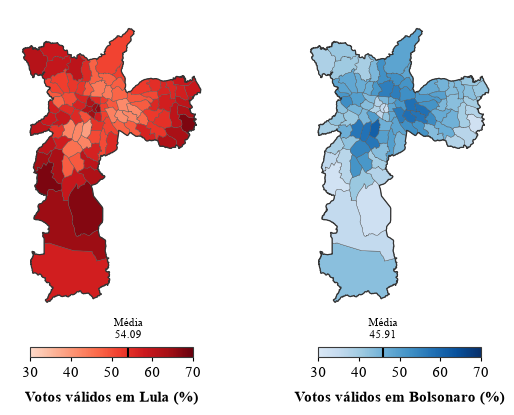

In [3]:
base = base.to_crs(epsg=31983)

variaveis = {
    'pct_val_lu': ('Votos válidos em Lula (%)', 'Reds'),
    'pct_val_fl': ('Votos válidos em Bolsonaro (%)', 'Blues'),
}

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'Liberation Serif', 'DejaVu Serif']
plt.rcParams['font.size'] = 12
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'

vals = base[list(variaveis)].to_numpy()
vmin = 5 * np.floor(np.nanmin(vals) / 5)
vmax = 5 * np.ceil(np.nanmax(vals) / 5)
norm = Normalize(vmin=vmin, vmax=vmax)

def cmap_cortado(nome, inicio=0.15):
    """Descarta o trecho quase branco do colormap."""
    cm = plt.get_cmap(nome)
    return LinearSegmentedColormap.from_list(
        f'{nome}_cut', cm(np.linspace(inicio, 1, 256))
    )

def centralizar_em_caixa(ax, mapa, margem=0.07):
    minx, miny, maxx, maxy = mapa.total_bounds
    dx, dy = maxx - minx, maxy - miny
    ax.set_xlim(minx - dx * margem, maxx + dx * margem)
    ax.set_ylim(miny - dy * margem, maxy + dy * margem)

fig, axes = plt.subplots(1, 2, figsize=(6, 4))
fig.patch.set_facecolor('white')
plt.subplots_adjust(left=0.02, right=0.98, top=0.98, bottom=0.2, wspace=0.0)

for ax, (col, (titulo, nome_cmap)) in zip(axes, variaveis.items()):
    cmap = cmap_cortado(nome_cmap)
    ax.set_facecolor('white')

    base.plot(
        column=col, cmap=cmap, norm=norm,
        linewidth=0.3, edgecolor='#555555',  
        missing_kwds={'color': '#D9D9D9'},
        ax=ax, zorder=2,
    )
    base.dissolve().boundary.plot(ax=ax, color='#333333', linewidth=0.9, zorder=3)

    ax.set_aspect('equal')
    centralizar_em_caixa(ax, base, margem=0.07)
    ax.set_axis_off()

    pos = ax.get_position()
    larg = pos.width * 0.8
    cax = fig.add_axes((pos.x0 + (pos.width - larg) / 2, 0.11, larg, 0.025))
    cb = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation='horizontal')
    cb.set_ticks(np.arange(vmin, vmax + 1, 10))
    cb.ax.tick_params(labelsize=11, length=3)
    cb.outline.set_edgecolor('#3a3a3a')
    cb.set_label(titulo, fontsize=11, fontweight='bold', labelpad=8)

    media = base[col].mean()
    cb.ax.axvline(media, color='black', linewidth=1.5)
    cb.ax.text(media, 1.6, f'Média\n{media:.2f}', transform=cb.ax.get_xaxis_transform(),
               ha='center', va='bottom', fontsize=8)

save_graph(fig, 'mapa_pct_val_lula_flavio_continuo')

2- Distribuição espacial do indicador de famílias beneficiárias do PBF por mil habitantes, por distrito da cidade de São Paulo

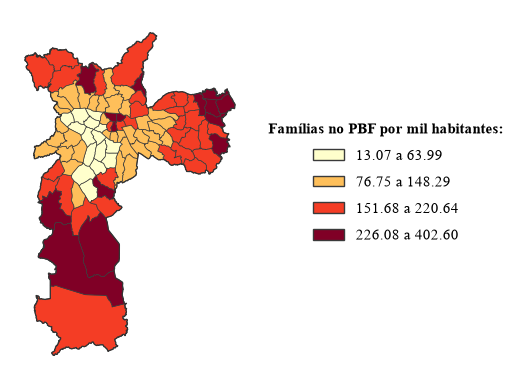

In [4]:
base = base.to_crs(epsg=31983)

base['pbf_mil_ha'] = base['pbf_mil_ha'].astype(float)

k = 4

classificador = mapclassify.NaturalBreaks(
    base['pbf_mil_ha'].dropna(),
    k=k
)

base['classe'] = float('nan')

base.loc[
    base['pbf_mil_ha'].notna(), 'classe'
] = classificador.yb

limites = classificador.bins

cmap = plt.get_cmap('YlOrRd', k)

cores = [cmap(i) for i in range(k)]

base['cor'] = base['classe'].map(
    lambda i: cores[int(i)] if not math.isnan(i) else '#D9D9D9' # type: ignore
)

labels_classe = []

for i in range(k):

    valores = base.loc[
        base['classe'] == i,
        'pbf_mil_ha'
    ]

    inferior = valores.min()
    superior = valores.max()

    labels_classe.append(
        f'{inferior:.2f} a {superior:.2f}'
    )

def centralizar_em_caixa(
    ax,
    mapa,
    margem=0.07
):

    minx, miny, maxx, maxy = mapa.total_bounds

    dx = maxx - minx
    dy = maxy - miny

    ax.set_xlim(
        minx - dx * margem,
        maxx + dx * margem
    )

    ax.set_ylim(
        miny - dy * margem,
        maxy + dy * margem
    )

plt.rcParams['font.family'] = 'serif'

plt.rcParams['font.serif'] = [
    'Times New Roman',
    'Liberation Serif',
    'DejaVu Serif'
]

plt.rcParams['font.size'] = 12

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'

fig, ax = plt.subplots(figsize=(6, 4))

fig.patch.set_facecolor('white')
ax.set_facecolor('white')

base.plot(
    color=base['cor'],
    linewidth=0.5,
    edgecolor='#3a3a3a',
    ax=ax,
    zorder=2
)

base.dissolve().boundary.plot(
    ax=ax,
    color='#333333',
    linewidth=0.9,
    zorder=3
)

ax.set_aspect('equal')

centralizar_em_caixa(
    ax,
    base,
    margem=0.07
)

handles = [
    Patch(
        facecolor=cores[i],
        edgecolor='#3a3a3a'
    )
    for i in range(k)
]

ax.legend(
    handles,
    labels_classe,
    title='Famílias no PBF por mil habitantes:',
    loc='center left',
    bbox_to_anchor=(1.02, 0.53),
    frameon=False,
    fontsize=11,
    title_fontproperties={
        'size': 11,
        'weight': 'bold'
    },
    labelspacing=0.8
)

ax.set_axis_off()

plt.subplots_adjust(
    left=0.04,
    right=0.76,
    top=0.96,
    bottom=0.04
)

save_graph(
    fig,
    'mapa_pbf_mil_hab_grupos'
)

plt.show()